# Data Exploration - Possible Asteroid Impacts with Earth

This dataset is a snapshot of data from Sentry, a system that monitors near earth asteroids and predicts their threat.

One row summarizes **one asteroid and its possible impact scenarios** in this
dataset. These are model estimates, not a record of observed collisions.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": False})

In [3]:
data_path = Path("./impacts.csv")
raw = pd.read_csv(data_path, dtype="string")
print("Loaded:", data_path.resolve())
print("Rows and columns:", raw.shape)
display(raw.head())

Loaded: /home/mati/developer/uj/data-science/2_data_exploration_advanced/impacts.csv
Rows and columns: (683, 11)


,Object Name,Period Start,Period End,Possible Impacts,Cumulative Impact Probability,Asteroid Velocity,Asteroid Magnitude,Asteroid Diameter (km),Cumulative Palermo Scale,Maximum Palermo Scale,Maximum Torino Scale
0,2006 WP1,2017,2017,1,5.2E-09,17.77,28.3,0.007,-8.31,-8.31,0
1,2013 YB,2017,2046,23,7.6E-05,8.98,31.4,0.002,-6.6,-6.96,0
2,2008 US,2017,2062,30,1.6E-05,18.33,31.4,0.002,-6.48,-6.87,0
3,2010 VR139,2017,2076,24,2E-07,4.99,26.7,0.016,-6.83,-6.95,0
4,2015 ME131,2017,2096,85,2.3E-08,19.46,19.2,0.497,-3.85,-4.3,0


### 1. Data preparation
| CSV column → short name | Meaning | Statistical role / caveats | Data type |
|---|---|---| --- |
| `Object Name` → `object_name` | Asteroid designation | Identifier | Identifier |
| `Period Start` → `period_start` | Earliest potential-impact year | Calendar year | Date (year; discrete) |
| `Period End` → `period_end` | Latest potential-impact year | Calendar year | Date (year; discrete) |
| `Possible Impacts` → `possible_impacts` | Number of potential impact solutions | Count | Numerical discrete |
| `Cumulative Impact Probability` → `impact_probability` | Combined probability across solutions | Fraction from 0 to 1 | Numerical continuous |
| `Asteroid Velocity` → `velocity_km_s` | Relative speed, km/s | Sentry's excess velocity excludes Earth's gravitational acceleration | Numerical continuous |
| `Asteroid Magnitude` → `absolute_magnitude` | Absolute magnitude H | Brightness scale; smaller H means brighter | Numerical continuous |
| `Asteroid Diameter (km)` → `diameter_km` | Estimated diameter, km | Approximate; often inferred from H and assumed reflectivity | Numerical continuous |
| `Cumulative Palermo Scale` → `palermo_cumulative` | Combined Palermo rating | Logarithmic risk scale | Numerical continuous |
| `Maximum Palermo Scale` → `palermo_max` | Highest individual Palermo rating | Logarithmic risk scale | Numerical continuous |
| `Maximum Torino Scale` → `torino_max` | Highest Torino rating | Ordered category from 0 to 10 | Categorical ordinal |

#### Palermo rating
The scale compares the likelihood of the detected potential impact with the average risk posed by objects of the same size or larger over the years until the date of the potential impact. This average risk from random impacts is known as the background risk. For convenience the scale is logarithmic, so, for examples, a Palermo Scale value of -2 indicates that the detected potential impact event is only 1% as likely as a random background event occurring in the intervening years, a value of zero indicates that the single event is just as threatening as the background hazard, and a value of +2 indicates an event that is 100 times more likely than a background impact by an object at least as large before the date of the potential impact in question.

#### Torino scale
The Torino Scale, adopted by the IAU in 1999, is a tool for categorizing potential Earth impact events. An integer scale ranging from 0 to 10 with associated color coding, it is intended primarily to facilitate public communication by the asteroid impact hazard monitoring community. The scale captures the likelihood and consequences of a potential impact event, but does not consider the time remaining until the potential impact. More extraordinary events are indicated by a higher Torino Scale value.

Definitions: [NASA/JPL Sentry object table](https://cneos.jpl.nasa.gov/sentry/)
and [Sentry API field documentation](https://ssd-api.jpl.nasa.gov/doc/sentry.html).

In [4]:
# Preparing the dataset: renaming columns to a simpler name, making number values have a numeric type instead of a string
column_names = {
    "Object Name": "object_name",
    "Period Start": "period_start",
    "Period End": "period_end",
    "Possible Impacts": "possible_impacts",
    "Cumulative Impact Probability": "impact_probability",
    "Asteroid Velocity": "velocity_km_s",
    "Asteroid Magnitude": "absolute_magnitude",
    "Asteroid Diameter (km)": "diameter_km",
    "Cumulative Palermo Scale": "palermo_cumulative",
    "Maximum Palermo Scale": "palermo_max",
    "Maximum Torino Scale": "torino_max",
}

asteroids = raw.copy()
asteroids.columns = asteroids.columns.str.strip()
if not asteroids.columns.is_unique:
    raise ValueError("Duplicate column names: inspect the CSV header before continuing.")
missing_columns = set(column_names) - set(asteroids.columns)
if missing_columns:
    raise ValueError(f"Unexpected CSV schema; missing columns: {sorted(missing_columns)}")

asteroids = asteroids.rename(columns=column_names)
numeric_columns = [name for name in column_names.values() if name != "object_name"]
conversion_failures = {}
for name in column_names.values():
    text = asteroids[name].str.strip().replace("", pd.NA)
    if name != "object_name":
        converted = pd.to_numeric(text, errors="coerce")
        conversion_failures[name] = int((text.notna() & converted.isna()).sum())

for name in numeric_columns:
    asteroids[name] = pd.to_numeric(asteroids[name], errors="coerce")

In [5]:
print("Non-empty values that could not be parsed (inspect raw if any are nonzero):")
pd.Series(conversion_failures, name="conversion_failures")

Non-empty values that could not be parsed (inspect raw if any are nonzero):


period_start          0
period_end            0
possible_impacts      0
impact_probability    0
velocity_km_s         0
absolute_magnitude    0
diameter_km           0
palermo_cumulative    0
palermo_max           0
torino_max            3
Name: conversion_failures, dtype: int64

In [6]:
asteroids.loc[asteroids["torino_max"].isna()]

,object_name,period_start,period_end,possible_impacts,impact_probability,velocity_km_s,absolute_magnitude,diameter_km,palermo_cumulative,palermo_max,torino_max
680,101955 Bennu (1999 RQ36),2175,2199,78,0.00037,5.99,20.2,0.49,-1.71,-2.32,<NA>
681,410777 (2009 FD),2185,2198,7,0.0016,15.87,22.1,0.16,-1.78,-1.83,<NA>
682,29075 (1950 DA),2880,2880,1,0.00012,14.1,17.6,1.3,-1.42,-1.42,<NA>


There are 3 records with `torino_max` set to a non-numeric value `(*)`, which gets changed to `<NA>` after conversion to a numeric type. The Torino scale is only defined for potential impacts less than 100 years into the future. For these records, `period_start` is later than 100 years in the future, so the Torino scale does not apply to them.
We will keep these records, because their other columns are still useful.

#### Understand the table and check data quality

Inspect shape, storage types, missing values, and duplicates.

In [7]:
print("Rows and columns:", asteroids.shape)
asteroids.info()
asteroids[numeric_columns].describe()

Rows and columns: (683, 11)
<class 'pandas.DataFrame'>
RangeIndex: 683 entries, 0 to 682
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   object_name         683 non-null    string 
 1   period_start        683 non-null    Int64  
 2   period_end          683 non-null    Int64  
 3   possible_impacts    683 non-null    Int64  
 4   impact_probability  683 non-null    Float64
 5   velocity_km_s       683 non-null    Float64
 6   absolute_magnitude  683 non-null    Float64
 7   diameter_km         683 non-null    Float64
 8   palermo_cumulative  683 non-null    Float64
 9   palermo_max         683 non-null    Float64
 10  torino_max          680 non-null    Int64  
dtypes: Float64(6), Int64(4), string(1)
memory usage: 65.5 KB


,period_start,period_end,possible_impacts,impact_probability,velocity_km_s,absolute_magnitude,diameter_km,palermo_cumulative,palermo_max,torino_max
count,683.0,683.0,683.0,683.0,683.0,683.0,683.0,683.0,683.0,680.0
mean,2062.573939,2099.68082,43.348463,0.000154,11.462577,26.158272,0.049378,-6.511552,-6.804012,0.0
std,43.501694,37.594698,113.77328,0.00252,6.067772,2.388296,0.156403,1.509189,1.476135,0.0
min,2017.0,2017.0,1.0,0.0,0.34,15.6,0.002,-10.98,-11.0,0.0
25%,2034.0,2090.0,2.0,0.0,7.24,25.0,0.01,-7.49,-7.79,0.0
50%,2061.0,2109.0,6.0,0.000002,10.5,26.4,0.017,-6.46,-6.79,0.0
75%,2085.0,2114.0,29.0,0.000016,14.81,27.8,0.033,-5.49,-5.865,0.0
max,2880.0,2880.0,1144.0,0.065,39.47,31.6,2.579,-1.42,-1.42,0.0


In [8]:
quality = pd.DataFrame({
    "dtype": asteroids.dtypes.astype(str),
    "missing_count": asteroids.isna().sum(),
    "missing_percent": asteroids.isna().mean().mul(100).round(2),
    "unique_values": asteroids.nunique(),
})
quality

,dtype,missing_count,missing_percent,unique_values
object_name,string,0,0.00,683
period_start,Int64,0,0.00,102
period_end,Int64,0,0.00,93
possible_impacts,Int64,0,0.00,140
impact_probability,Float64,0,0.00,340
velocity_km_s,Float64,0,0.00,571
absolute_magnitude,Float64,0,0.00,118
diameter_km,Float64,0,0.00,122
palermo_cumulative,Float64,0,0.00,392
palermo_max,Float64,0,0.00,378


In [9]:
print("Identical rows:", asteroids.duplicated().sum())
print("Repeated non-missing object names:",
      asteroids["object_name"].dropna().duplicated().sum())

Identical rows: 0
Repeated non-missing object names: 0


**Flag questionable values** - create a table, where each row describes if the same row of `asteroids` has questionable values

In [10]:
flags = pd.DataFrame(index=asteroids.index)
p = asteroids["impact_probability"]
flags["probability_outside_0_1"] = (p < 0) | (p > 1)
flags["nonpositive_diameter"] = asteroids["diameter_km"] <= 0
flags["negative_velocity"] = asteroids["velocity_km_s"] < 0
flags["reversed_year_range"] = asteroids["period_start"] > asteroids["period_end"]
for name in ["period_start", "period_end", "possible_impacts", "torino_max"]:
    flags[f"{name}_not_integer"] = asteroids[name].mod(1).ne(0)
flags["negative_impact_count"] = asteroids["possible_impacts"] < 0
flags["torino_outside_0_10"] = ~asteroids["torino_max"].between(0, 10)

In [11]:
flags.sum().rename("flagged_rows")

probability_outside_0_1         0
nonpositive_diameter            0
negative_velocity               0
reversed_year_range             0
period_start_not_integer        0
period_end_not_integer          0
possible_impacts_not_integer    0
torino_max_not_integer          0
negative_impact_count           0
torino_outside_0_10             0
Name: flagged_rows, dtype: Int64

As we can see, this dataset doesn't have any strange/questionable values outside of the three `(*)` values in the `torino_max` column. In the next section, I will explore distributions and relationships between variables.

### 2. Distributions and relationships

- I expect more asteroids with bigger diameter, due to observation bias (small asteroids would be detected less often). More formally, I expect a left skew.
- I expect that cumulative probability be very heavily skewed towards smaller probabilities, because if there were lots of dangerous asteroids, we would hear about it more often.
- I expect there to be no correlation between asteroid size and probability of impact, because what matters is the position of the asteroid with respect to Earth, not its size.
- I expect a strong correlation between asteroid size and its brightness.


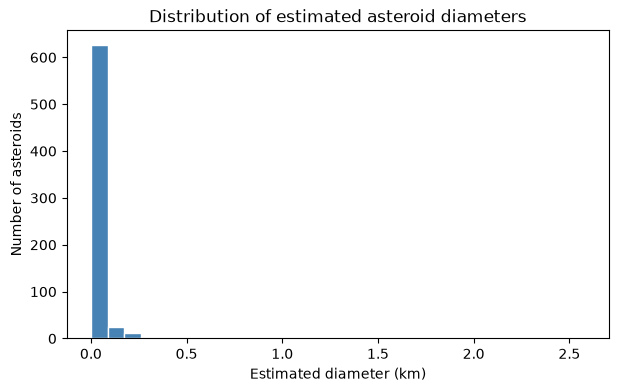

In [12]:
fig, ax = plt.subplots()
ax.hist(asteroids["diameter_km"], bins=30, color="steelblue", edgecolor="white")
ax.set(xlabel="Estimated diameter (km)", ylabel="Number of asteroids",
       title="Distribution of estimated asteroid diameters")
plt.show()

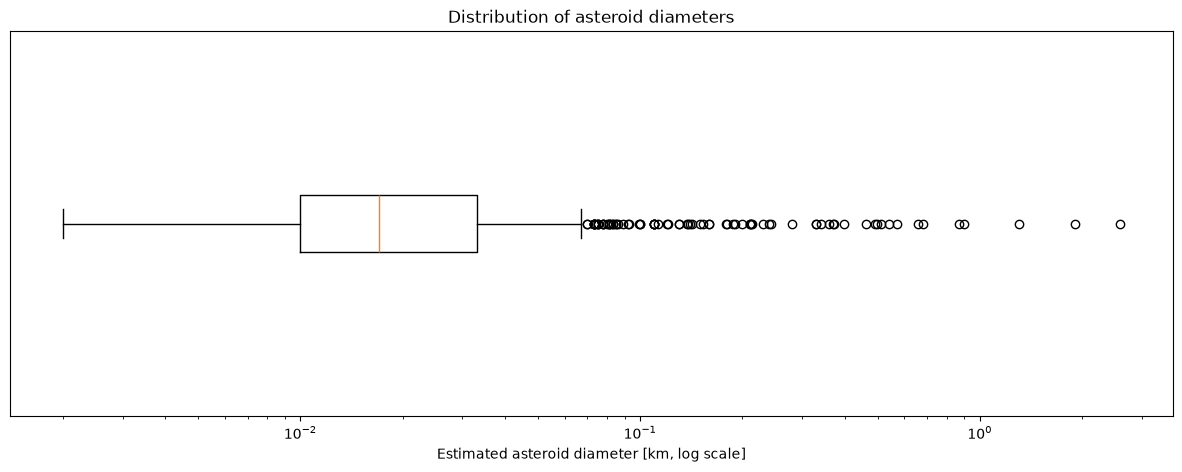

In [13]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.boxplot(asteroids["diameter_km"], orientation="horizontal")
ax.semilogx()
ax.set_xlabel("Estimated asteroid diameter [km, log scale]")
ax.set_yticks([])
ax.set_title("Distribution of asteroid diameters")
plt.show()

In [14]:
# >0 indicates right skew, <0 indicates left skew
asteroids["diameter_km"].skew()

np.float64(10.371823152185494)

My expectation about distribution of asteroid diameters was wrong - there are way more small (on the order of 10s of meters) asteroids than big ones. The distribution is right skewed.

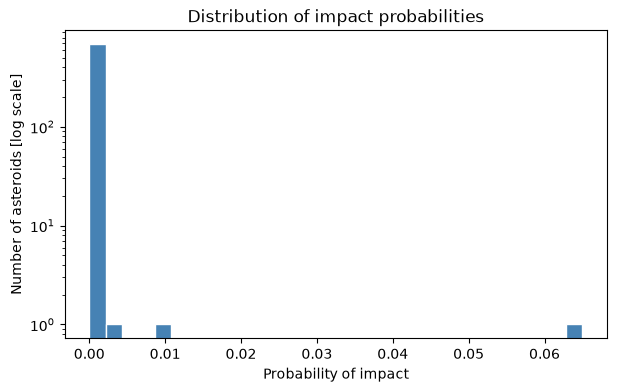

In [15]:
fig, ax = plt.subplots()
ax.hist(asteroids["impact_probability"], bins=30, color="steelblue", edgecolor="white")
ax.set(xlabel="Probability of impact", ylabel="Number of asteroids [log scale]",
       title="Distribution of impact probabilities")
ax.semilogy()
plt.show()

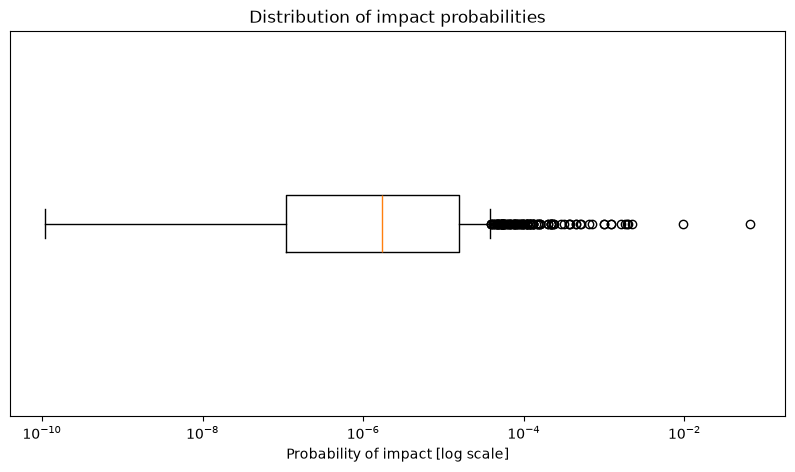

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(asteroids["impact_probability"], orientation="horizontal")
ax.semilogx()
ax.set_xlabel("Probability of impact [log scale]")
ax.set_yticks([])
ax.set_title("Distribution of impact probabilities")
plt.show()

My assumption about impact probabilities was correct - most probabilities are very small (from $10^{-7}$ to $10^{-5}$), with some outliers.

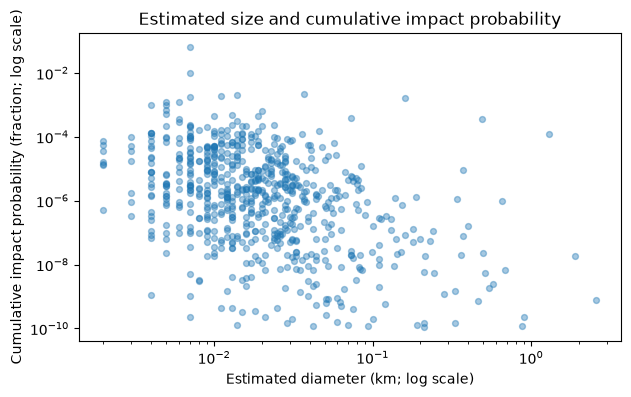

Correlation: 


np.float64(-0.013628996297543156)

In [17]:
fig, ax = plt.subplots()
ax.scatter(asteroids["diameter_km"], asteroids["impact_probability"], s=18, alpha=0.4)
ax.set(xscale="log", yscale="log", xlabel="Estimated diameter (km; log scale)",
       ylabel="Cumulative impact probability (fraction; log scale)",
       title="Estimated size and cumulative impact probability")
plt.show()
print("Correlation: ")
asteroids.corr(numeric_only=True)["diameter_km"]["impact_probability"]

My prediction about size and impact probability was also correct - there is little correlation between these 2 variables.

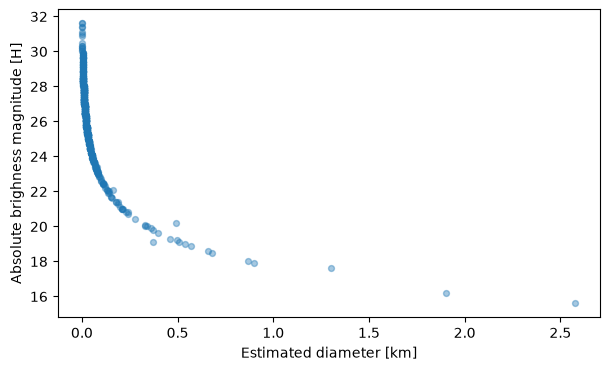

In [18]:
fig, ax = plt.subplots()
ax.scatter(asteroids["diameter_km"], asteroids["absolute_magnitude"], s=18, alpha=0.4)
ax.set_xlabel("Estimated diameter [km]")
ax.set_ylabel("Absolute brighness magnitude [H]")
plt.show()


This prediction is also correct, the bigger the asteroid, the more light it reflects (lower brightness magnitude = brighter object).

### 3. Impact risk analysis

Expectations:
   - The size of the asteroid shouldn't have a correlation with the Palermo rating. The Palermo rating compares the likelihood of the detected potential impact with the average risk posed by objects of the same size or larger over the years until the date of the potential impact.

Let's explore the Torino rating first. Remember, the Torino rating is an integer scale ranging from 0 to 10 with associated color coding, it is intended primarily to facilitate public communication by the asteroid impact hazard monitoring community.

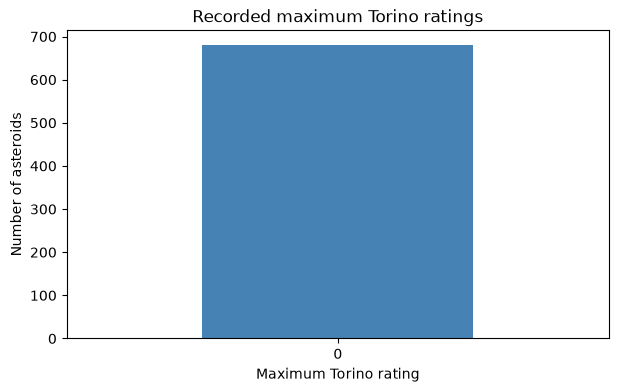

In [19]:
torino_counts = asteroids["torino_max"].value_counts().sort_index()
fig, ax = plt.subplots()
torino_counts.plot.bar(ax=ax, color="steelblue", rot=0)
ax.set(xlabel="Maximum Torino rating", ylabel="Number of asteroids",
       title="Recorded maximum Torino ratings")
plt.show()

It turns out ALL asteroids in this dataset have torino ratings == 0. This means all of them have near-zero or zero chance of impact. This is not a very diverse dataset. We will skip analisying the Torino rating.

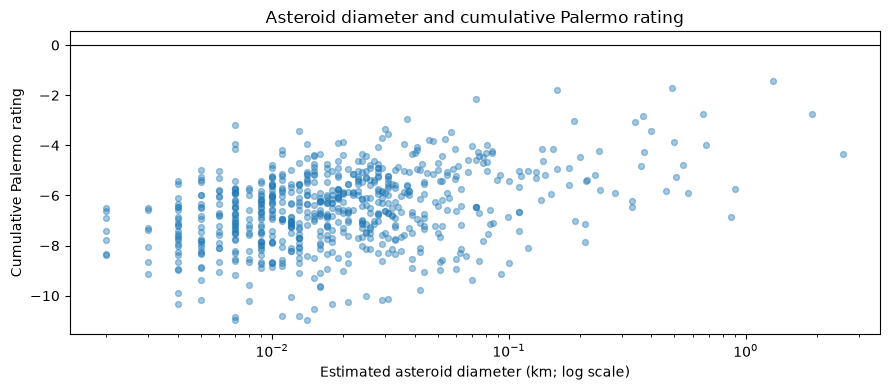

Correlation: 


np.float64(0.2675899723748633)

In [20]:
plot_mask = (
    (asteroids["diameter_km"] > 0)
    & np.isfinite(asteroids["diameter_km"])
    & np.isfinite(asteroids["palermo_cumulative"])
).fillna(False)
plot_data = asteroids.loc[plot_mask]

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(plot_data["diameter_km"], plot_data["palermo_cumulative"], s=18, alpha=0.4)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("Estimated asteroid diameter (km; log scale)")
ax.set_ylabel("Cumulative Palermo rating")
ax.set_title("Asteroid diameter and cumulative Palermo rating")
fig.tight_layout()
plt.show()
print("Correlation: ")
plot_data.corr(numeric_only=True)["diameter_km"]["palermo_cumulative"]

Unexpectedly, larger asteroids tend to have higher cumulative Palermo ratings.

To be honest, I can't think of a great explanation for this. A possible one is that although the
scale compares risk with a size-dependent background, this does not remove all
association with size. Maybe because large impacts are rarer, the same impact probability
and time horizon give a higher rating for a larger asteroid?

## 4. Do the two rankings pick the same asteroids?

**Question:** Do the ten asteroids with the highest impact probabilities also
have the ten highest cumulative Palermo ratings?

Impact probability tells us how likely an impact is in this snapshot. The Palermo
rating also accounts for estimated impact energy and the time until a possible
impact, compared with the background risk. A higher rating can still be negative:
for example, -2 is higher than -5.

We will rank all objects with both values available, compare the two lists, and
look at a few examples. We will not apply a minimum size or probability filter.

In [82]:
# Use the same set of objects for both rankings.
ranking_data = asteroids.dropna(
    subset=["object_name", "impact_probability", "palermo_cumulative"]
).copy()
print("Objects included:", len(ranking_data))
print("Objects excluded because of missing values:", len(asteroids) - len(ranking_data))

# Rank 1 means the highest value. Equal values receive the same rank.
ranking_data["probability_rank"] = ranking_data["impact_probability"].rank(
    ascending=False, method="min"
).astype("Int64")
ranking_data["palermo_rank"] = ranking_data["palermo_cumulative"].rank(
    ascending=False, method="min"
).astype("Int64")

comparison_columns = [
    "object_name", "probability_rank", "palermo_rank", "diameter_km",
    "impact_probability", "palermo_cumulative", "period_start", "period_end",
]

def show_objects(table):
    # Scientific notation keeps small probabilities readable without changing the data.
    view = table[comparison_columns].copy()
    view["impact_probability"] = view["impact_probability"].map(lambda p: f"{p:.2e}")
    display(view.reset_index(drop=True))

Objects included: 683
Objects excluded because of missing values: 0


### Compare the top ten lists

Sort each measure from highest to lowest, then keep ten objects. If values are
equal, sort those objects by name so the result is repeatable. The rank columns
show each object's position in the full dataset, including shared ranks for ties.

In [83]:
top_probability = ranking_data.sort_values(
    ["impact_probability", "object_name"], ascending=[False, True]
).head(10)

top_palermo = ranking_data.sort_values(
    ["palermo_cumulative", "object_name"], ascending=[False, True]
).head(10)

print("Top ten by cumulative impact probability:")
show_objects(top_probability)
print("Top ten by cumulative Palermo rating:")
show_objects(top_palermo)

Top ten by cumulative impact probability:


,object_name,probability_rank,palermo_rank,diameter_km,impact_probability,palermo_cumulative,period_start,period_end
0,2010 RF12,1,11,0.007,6.50e-02,-3.2,2095,2115
1,2006 JY26,2,24,0.007,9.70e-03,-3.93,2073,2110
2,2000 SG344,3,8,0.037,2.20e-03,-2.93,2069,2113
3,2012 HG2,4,25,0.014,2.00e-03,-3.94,2053,2116
4,2016 RD34,5,36,0.011,1.90e-03,-4.17,2051,2093
5,2015 YJ,6,32,0.007,1.80e-03,-4.13,2042,2115
6,410777 (2009 FD),7,3,0.16,1.60e-03,-1.78,2185,2198
7,2014 JR24,8,137,0.005,1.20e-03,-5.26,2069,2115
8,2016 VB1,8,102,0.006,1.20e-03,-5.02,2071,2115
9,2011 AM37,10,163,0.004,1.00e-03,-5.43,2044,2114


Top ten by cumulative Palermo rating:


,object_name,probability_rank,palermo_rank,diameter_km,impact_probability,palermo_cumulative,period_start,period_end
0,29075 (1950 DA),45,1,1.3,1.20e-04,-1.42,2880,2880
1,101955 Bennu (1999 RQ36),19,2,0.49,3.70e-04,-1.71,2175,2199
2,410777 (2009 FD),7,3,0.16,1.60e-03,-1.78,2185,2198
3,2017 BL30,18,4,0.073,3.80e-04,-2.17,2029,2052
4,2010 AU118,593,5,1.9,1.80e-08,-2.73,2020,2112
5,1979 XB,391,6,0.657,9.90e-07,-2.75,2056,2113
6,99942 Apophis (2004 MN4),203,7,0.37,8.90e-06,-2.83,2060,2105
7,2000 SG344,3,8,0.037,2.20e-03,-2.93,2069,2113
8,2016 NL56,367,9,0.188,1.30e-06,-3.04,2019,2116
9,2007 FT3,380,10,0.34,1.10e-06,-3.08,2019,2114


### How much do the lists overlap?


In [85]:
shared_objects = top_probability.loc[
    top_probability["object_name"].isin(top_palermo["object_name"])
].copy()

print(f"Objects in both top-ten lists: {len(shared_objects)} out of 10")
show_objects(shared_objects)
print(f"Median diameter in the probability list: {top_probability['diameter_km'].median():.3f} km")
print(f"Median diameter in the Palermo list: {top_palermo['diameter_km'].median():.3f} km")

Objects in both top-ten lists: 2 out of 10


,object_name,probability_rank,palermo_rank,diameter_km,impact_probability,palermo_cumulative,period_start,period_end
0,2000 SG344,3,8,0.037,2.20e-03,-2.93,2069,2113
1,410777 (2009 FD),7,3,0.16,1.60e-03,-1.78,2185,2198


Median diameter in the probability list: 0.007 km
Median diameter in the Palermo list: 0.355 km


**Result:** Only **2 of the 10 objects** appear in both lists: **2000 SG344**
and **410777 (2009 FD)**. So the two rankings give quite different results.

The median diameter is **0.007 km (7 m)** in the probability list and
**0.355 km (355 m)** in the Palermo list. In this dataset, the Palermo top ten
contains larger asteroids overall.

### Look at three examples

Let's compare the highest-probability object, the highest Palermo-rated object,
and one object that appears in both lists.

In [86]:
example_names = ["2010 RF12", "29075 (1950 DA)", "410777 (2009 FD)"]
examples = ranking_data.set_index("object_name").loc[example_names].reset_index()
show_objects(examples)

,object_name,probability_rank,palermo_rank,diameter_km,impact_probability,palermo_cumulative,period_start,period_end
0,2010 RF12,1,11,0.007,6.50e-02,-3.2,2095,2115
1,29075 (1950 DA),45,1,1.3,1.20e-04,-1.42,2880,2880
2,410777 (2009 FD),7,3,0.16,1.60e-03,-1.78,2185,2198


- `2010 RF12` has the highest cumulative impact probability: 6.5%.
  Its estimated diameter is only 7 m. Its Palermo rating is -3.20,
  which puts it 11th in that ranking. Its possible-impact years are 2095–2115.
- `29075 (1950 DA)` ranks first by Palermo rating (-1.42), but only
  45th by probability (0.012%It is much larger, at about 1.3 km
  across. Its possible-impact year is 2880.
- `410777 (2009 FD)` appears in both lists: 7th by probability (0.16%
  and 3rd by Palermo rating (-1.78). Its estimated diameter is 160 m,
  and its possible-impact years are 2185–2198.

These examples show why a higher probability does not always mean a higher
Palermo rating. Size affects the estimated impact energy, and timing matters too.
For example, 1950 DA has a much lower probability than 2010 RF12 but a higher
Palermo rating. Their size and timing also differ, so this comparison cannot tell
us exactly how much each factor changes the rating.

### What can we conclude?

The rankings answer different questions. The probability list shows which
objects have the highest estimated chance of impact. The Palermo list compares
potential impacts with the background risk while also accounting for energy and
time. Probability alone does not describe how serious an impact could be.


## Final reflection

**Two findings:**

1. Most asteroids in this dataset are small, with a few much larger objects.
   The median diameter is **0.017 km (17 m)**, while the mean is about
   **0.049 km (49 m)**.
2. A higher impact probability does not always mean a higher Palermo rating.
   Only **2 objects** appear in both top-ten lists: **2000 SG344** and
   **410777 (2009 FD)**. The rankings differ because the Palermo rating also
   accounts for impact energy and timing relative to the background risk.

**One limitation:**

All 680 objects with a numerical Torino rating have a rating of 0. The other
3 objects have no applicable Torino rating. Since the recorded ratings are all
the same, this dataset cannot show how asteroids with different Torino ratings
compare or how those ratings relate to size and impact probability. A rating of
0 also does not necessarily mean that the impact probability is exactly zero.
